# Obtención de Datos Mediante APIs en Python

Alguna de las formas de obtención de datos es a través de **APIs (Application Programming Interfaces)**. Las APIs son una forma eficiente de acceder a datos y servicios en línea. Aprenderemos a realizar solicitudes a través de Python utilizando la popular biblioteca `requests`.

## Introducción a las APIs

Una API (Application Programming Interface) es un conjunto de reglas y protocolos que permiten a diferentes aplicaciones interactuar entre sí. Las APIs permiten a las aplicaciones solicitar datos o realizar acciones en un servidor remoto de manera estructurada y estandarizada.

![imagen](./img/http.PNG)

## Protocolo HTTP

El Protocolo de Transferencia de Hipertexto (HTTP) es el protocolo subyacente utilizado en la World Wide Web. Se utiliza para solicitar y transmitir datos en la web. 

![imagen](./img/peticion_respuesta.PNG)

Aquí tienes un ejemplo de arquitectura:

![imagen](./img/arquitectura_servidor.PNG)

Las solicitudes HTTP se pueden realizar utilizando varios métodos, siendo los más comunes:

* **GET**: Para recuperar datos.
* **POST**: Para enviar datos al servidor.
* **PUT**: Para actualizar datos en el servidor.
* **DELETE**: Para eliminar datos en el servidor.


![imagen](./img/documentacion_api.PNG)

Podemos hacer una petición:

![imagen](./img/parametros.PNG)

y obtener como respuesta diferentes códigos:

![imagen](./img/status_codes.PNG)

Ejemplo de la API de Marvel. La URL se construye como *urlbase* + *endpoint* + *params*

En general para acceder a un servicio de una API la URL se construye como *urlbase* + *endpoint* + *params*

![imagen](./img/MarvelAccessPoints.png)

## Biblioteca ``requests``

La biblioteca requests es una de las más populares para realizar solicitudes HTTP en Python. Permite enviar solicitudes y procesar respuestas de una manera sencilla y eficiente.

In [1]:
# %pip install requests

In [2]:
# Importamos librerias
import requests
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

## Primera petición

In [3]:
url = "https://pbs.twimg.com/profile_images/616689518968762368/rkhjKqNb.jpg"
image = requests.get(url)

In [4]:
image


<Response [200]>

In [5]:
image.content[:200]

b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xe2\x02\xa0ICC_PROFILE\x00\x01\x01\x00\x00\x02\x90lcms\x040\x00\x00mntrRGB XYZ \x07\xdf\x00\x07\x00\x02\x00\x13\x00\x1a\x005acspAPPL\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\xf6\xd6\x00\x01\x00\x00\x00\x00\xd3-lcms\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0bdesc\x00\x00\x01\x08\x00\x00\x008cprt\x00\x00\x01@\x00\x00\x00Nwtpt\x00\x00'

In [6]:
# plt.show(image)

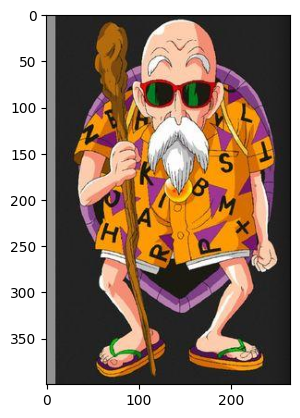

In [8]:
import io
plt.imshow(Image.open(io.BytesIO(image.content)));

### Mediante pandas

In [9]:
df_inflation = pd.read_csv('https://datahub.io/core/inflation/r/inflation-gdp.csv')
df_inflation.head()

,Country,Country Code,Year,Inflation
0,Aruba,ABW,1985,4.032258
1,Aruba,ABW,1986,1.073966
2,Aruba,ABW,1987,3.643045
3,Aruba,ABW,1988,3.121868
4,Aruba,ABW,1989,3.991628


In [10]:
df_inflation[df_inflation['Country'] == "Spain"]

,Country,Country Code,Year,Inflation
2904,Spain,ESP,1960,1.177771
2905,Spain,ESP,1961,0.809253
2906,Spain,ESP,1962,5.706477
2907,Spain,ESP,1963,8.743698
2908,Spain,ESP,1964,6.979247
...,...,...,...,...
2964,Spain,ESP,2020,-0.322753
2965,Spain,ESP,2021,3.093135
2966,Spain,ESP,2022,8.390576
2967,Spain,ESP,2023,3.532361


## Bajar datos de Bicimad

In [11]:
url = 'https://divvy-tripdata.s3.amazonaws.com/202106-divvy-tripdata.zip'
r = requests.get(url)

In [12]:
# r

In [13]:
# r.content

In [14]:
# Guardamos el zip
filename = 'data/bicis.zip'
with open(filename, 'wb') as f:
   f.write(r.content)

In [15]:
# Extraemos lo que hay dentro
filename = './data/bicis.zip'
with zipfile.ZipFile(filename, 'r') as zip_ref:
    zip_ref.extractall("data/")

In [16]:
## Leemos los datos
datos_bicis = pd.read_csv('data/202106-divvy-tripdata.csv', nrows=10000)

In [17]:
# Vemos qué pinta tienen
datos_bicis.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,99FEC93BA843FB20,electric_bike,2021-06-13 14:31:28,2021-06-13 14:34:11,NaN,NaN,NaN,NaN,41.80,-87.59,41.80,-87.60,member
1,06048DCFC8520CAF,electric_bike,2021-06-04 11:18:02,2021-06-04 11:24:19,NaN,NaN,NaN,NaN,41.79,-87.59,41.80,-87.60,member
2,9598066F68045DF2,electric_bike,2021-06-04 09:49:35,2021-06-04 09:55:34,NaN,NaN,NaN,NaN,41.80,-87.60,41.79,-87.59,member
3,B03C0FE48C412214,electric_bike,2021-06-03 19:56:05,2021-06-03 20:21:55,NaN,NaN,NaN,NaN,41.78,-87.58,41.80,-87.60,member
4,B9EEA89F8FEE73B7,electric_bike,2021-06-04 14:05:51,2021-06-04 14:09:59,NaN,NaN,NaN,NaN,41.80,-87.59,41.79,-87.59,member


In [18]:
datos_bicis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ride_id             10000 non-null  object 
 1   rideable_type       10000 non-null  object 
 2   started_at          10000 non-null  object 
 3   ended_at            10000 non-null  object 
 4   start_station_name  843 non-null    object 
 5   start_station_id    843 non-null    object 
 6   end_station_name    702 non-null    object 
 7   end_station_id      702 non-null    object 
 8   start_lat           10000 non-null  float64
 9   start_lng           10000 non-null  float64
 10  end_lat             9991 non-null   float64
 11  end_lng             9991 non-null   float64
 12  member_casual       10000 non-null  object 
dtypes: float64(4), object(9)
memory usage: 1015.8+ KB


In [19]:
datos_bicis['member_casual'].unique()

array(['member', 'casual'], dtype=object)

In [20]:
datos_bicis['rideable_type'].unique()

array(['electric_bike', 'classic_bike', 'docked_bike'], dtype=object)

## Api chucknorris

[Enlace API](https://api.chucknorris.io/)

In [21]:
url = "https://api.chucknorris.io/jokes/random"  # Reemplaza con la URL de la API que deseas acceder.

response = requests.get(url)
response.json()
if response.status_code == 200:  # Código 200 indica una respuesta exitosa.
    data = response.json()  # Analizar la respuesta JSON.
    #print(data["value"])
    print(data)
else:
    print("Error en la solicitud: ", response.status_code)
data["value"]

{'categories': [], 'created_at': '2020-01-05 13:42:21.179347', 'icon_url': 'https://api.chucknorris.io/img/avatar/chuck-norris.png', 'id': 'Y9HFe6O4RqiWyumepjl1tQ', 'updated_at': '2020-01-05 13:42:21.179347', 'url': 'https://api.chucknorris.io/jokes/Y9HFe6O4RqiWyumepjl1tQ', 'value': 'When Chuck Norris has to lay low from the cops, his alias is Not Chuck Norris. He has photo ID and everything.'}


'When Chuck Norris has to lay low from the cops, his alias is Not Chuck Norris. He has photo ID and everything.'

In [22]:
def get_joke(url):
    response = requests.get(url)

    if response.status_code == 200:  # Código 200 indica una respuesta exitosa.
        data = response.json()  # Analizar la respuesta JSON.
        return data
    else:
        print("Error en la solicitud: ", response.status_code)

In [23]:
url = "https://api.chucknorris.io/jokes/categories"
get_joke(url)

['animal',
 'career',
 'celebrity',
 'dev',
 'explicit',
 'fashion',
 'food',
 'history',
 'money',
 'movie',
 'music',
 'political',
 'religion',
 'science',
 'sport',
 'travel']

In [24]:
url = "https://api.chucknorris.io/jokes/random?category=animal"
get_joke(url)

{'categories': ['animal'],
 'created_at': '2020-01-05 13:42:19.576875',
 'icon_url': 'https://api.chucknorris.io/img/avatar/chuck-norris.png',
 'id': 'bmom6jqftpqgokh8adtolw',
 'updated_at': '2020-01-05 13:42:19.576875',
 'url': 'https://api.chucknorris.io/jokes/bmom6jqftpqgokh8adtolw',
 'value': 'Chuck Norris once rode a nine foot grizzly bear through an automatic car wash, instead of taking a shower.'}

In [25]:
joke = get_joke(url)
joke["value"]

'Chuck Norris once rode a nine foot grizzly bear through an automatic car wash, instead of taking a shower.'

In [26]:
url = "https://api.chucknorris.io/jokes/random"
parametros = {
    "category": "animal"
}
# requests se encarga de añadir el "?" y concatenar todo correctamente
response = requests.get(url, params=parametros)

print("URL construida automáticamente:", response.url)
response.json()['value']

URL construida automáticamente: https://api.chucknorris.io/jokes/random?category=animal


'Chuck Norris can skeletize a cow in two minutes.'

### POST
Nota: REQUIERE API KEY

In [27]:
# URL de la API de prueba
url = "https://reqres.in/api/users"

# Datos a enviar en el request
data = {
    "name": "Juan Pérez",
    "job": "Científico de Datos"
}

# Enviar solicitud POST
response = requests.post(url, json=data)

# Verificar la respuesta
if response.status_code == 201:  # Código 201 = Creado exitosamente
    print("Usuario creado con éxito.")
    print("Respuesta de la API:", response.json())  # Mostrar datos devueltos
else:
    print("Error en la solicitud:", response.status_code)

Usuario creado con éxito.
Respuesta de la API: {'name': 'Juan Pérez', 'job': 'Científico de Datos', 'id': '173', 'createdAt': '2026-11-06T08:02:49.229Z', 'support': {'url': 'https://reqres.in/go/posthog', 'text': 'PostHog ingests and stores your analytics, errors, replays, and business data so you and your agents can query and act on it. Get started.', 'sponsored_by': 'PostHog'}, '_meta': {'powered_by': 'ReqRes', 'docs_url': 'https://app.reqres.in/documentation', 'upgrade_url': 'https://app.reqres.in/upgrade', 'example_url': 'https://app.reqres.in/examples/notes-app', 'variant': 'key_v1', 'message': 'You are on the shared demo (no personal key), which has a low daily limit. A free account gives you your own key with 250 requests a day, plus request logs and your own collections.', 'cta': {'label': 'Get a free key', 'url': 'https://app.reqres.in/?utm_source=reqres_api&utm_medium=json&utm_campaign=demo_meta_key'}, 'context': 'keyless_success'}}


## Datos del espacio

In [28]:
# URL de la API de Open Notify (Astronautas actualmente en el espacio)
url_total = "http://api.open-notify.org/astros.json"

response = requests.get(url_total)
print("URL:", url_total)
print("Código de estado:", response.status_code)

URL: http://api.open-notify.org/astros.json
Código de estado: 200


In [29]:
print(url_total)

http://api.open-notify.org/astros.json


In [30]:
print(response.status_code)
#type(response.content)
#response.json()

200


In [31]:
type(response.content)


bytes

In [32]:
astronautas = response.json()
astronautas

{'people': [{'craft': 'ISS', 'name': 'Oleg Kononenko'},
  {'craft': 'ISS', 'name': 'Nikolai Chub'},
  {'craft': 'ISS', 'name': 'Tracy Caldwell Dyson'},
  {'craft': 'ISS', 'name': 'Matthew Dominick'},
  {'craft': 'ISS', 'name': 'Michael Barratt'},
  {'craft': 'ISS', 'name': 'Jeanette Epps'},
  {'craft': 'ISS', 'name': 'Alexander Grebenkin'},
  {'craft': 'ISS', 'name': 'Butch Wilmore'},
  {'craft': 'ISS', 'name': 'Sunita Williams'},
  {'craft': 'Tiangong', 'name': 'Li Guangsu'},
  {'craft': 'Tiangong', 'name': 'Li Cong'},
  {'craft': 'Tiangong', 'name': 'Ye Guangfu'}],
 'number': 12,
 'message': 'success'}

In [33]:
# Obtener el nombre del primer astronauta
astronautas["people"][0]["name"]

'Oleg Kononenko'

In [34]:
# Obtener la nave (craft) en la que se encuentra el primer astronauta
astronautas["people"][0]["craft"]

'ISS'

In [35]:
# Vemos los datos con un bucle
for astronauta in astronautas["people"]:
    print(astronauta)

{'craft': 'ISS', 'name': 'Oleg Kononenko'}
{'craft': 'ISS', 'name': 'Nikolai Chub'}
{'craft': 'ISS', 'name': 'Tracy Caldwell Dyson'}
{'craft': 'ISS', 'name': 'Matthew Dominick'}
{'craft': 'ISS', 'name': 'Michael Barratt'}
{'craft': 'ISS', 'name': 'Jeanette Epps'}
{'craft': 'ISS', 'name': 'Alexander Grebenkin'}
{'craft': 'ISS', 'name': 'Butch Wilmore'}
{'craft': 'ISS', 'name': 'Sunita Williams'}
{'craft': 'Tiangong', 'name': 'Li Guangsu'}
{'craft': 'Tiangong', 'name': 'Li Cong'}
{'craft': 'Tiangong', 'name': 'Ye Guangfu'}


In [36]:
# Preparamos el diccionario para pasarlo a Pandas
astro_dict = {
    "name": [],
    "craft": []
}

for astronauta in astronautas["people"]:
    astro_dict["name"].append(astronauta["name"])
    astro_dict["craft"].append(astronauta["craft"])
    
astro_dict
  

{'name': ['Oleg Kononenko',
  'Nikolai Chub',
  'Tracy Caldwell Dyson',
  'Matthew Dominick',
  'Michael Barratt',
  'Jeanette Epps',
  'Alexander Grebenkin',
  'Butch Wilmore',
  'Sunita Williams',
  'Li Guangsu',
  'Li Cong',
  'Ye Guangfu'],
 'craft': ['ISS',
  'ISS',
  'ISS',
  'ISS',
  'ISS',
  'ISS',
  'ISS',
  'ISS',
  'ISS',
  'Tiangong',
  'Tiangong',
  'Tiangong']}

In [37]:
astrodf = pd.DataFrame(astro_dict)
astrodf

,name,craft
0,Oleg Kononenko,ISS
1,Nikolai Chub,ISS
2,Tracy Caldwell Dyson,ISS
3,Matthew Dominick,ISS
4,Michael Barratt,ISS
5,Jeanette Epps,ISS
6,Alexander Grebenkin,ISS
7,Butch Wilmore,ISS
8,Sunita Williams,ISS
9,Li Guangsu,Tiangong


In [38]:
# En lugar de filtrar por la URL de la API, filtramos directamente en nuestro DataFrame
# Por ejemplo, buscar solo los astronautas que están en la Estación Espacial Internacional (ISS)
tripulacion_iss = astrodf[astrodf['craft'] == 'ISS']
tripulacion_iss

,name,craft
0,Oleg Kononenko,ISS
1,Nikolai Chub,ISS
2,Tracy Caldwell Dyson,ISS
3,Matthew Dominick,ISS
4,Michael Barratt,ISS
5,Jeanette Epps,ISS
6,Alexander Grebenkin,ISS
7,Butch Wilmore,ISS
8,Sunita Williams,ISS


In [39]:
url_total

'http://api.open-notify.org/astros.json'

In [40]:
rm_url = "https://rickandmortyapi.com/api"
path = "/character"
url_total = rm_url + path

response = requests.get(url_total)

In [41]:
response

<Response [200]>

In [42]:
rm_url

'https://rickandmortyapi.com/api'

In [43]:
response.json()

{'info': {'count': 826,
  'pages': 42,
  'next': 'https://rickandmortyapi.com/api/character?page=2',
  'prev': None},
 'results': [{'id': 1,
   'name': 'Rick Sanchez',
   'status': 'Alive',
   'species': 'Human',
   'type': '',
   'gender': 'Male',
   'origin': {'name': 'Earth (C-137)',
    'url': 'https://rickandmortyapi.com/api/location/1'},
   'location': {'name': 'Citadel of Ricks',
    'url': 'https://rickandmortyapi.com/api/location/3'},
   'image': 'https://rickandmortyapi.com/api/character/avatar/1.jpeg',
   'episode': ['https://rickandmortyapi.com/api/episode/1',
    'https://rickandmortyapi.com/api/episode/2',
    'https://rickandmortyapi.com/api/episode/3',
    'https://rickandmortyapi.com/api/episode/4',
    'https://rickandmortyapi.com/api/episode/5',
    'https://rickandmortyapi.com/api/episode/6',
    'https://rickandmortyapi.com/api/episode/7',
    'https://rickandmortyapi.com/api/episode/8',
    'https://rickandmortyapi.com/api/episode/9',
    'https://rickandmortyapi.

In [44]:
response.json()['results']

[{'id': 1,
  'name': 'Rick Sanchez',
  'status': 'Alive',
  'species': 'Human',
  'type': '',
  'gender': 'Male',
  'origin': {'name': 'Earth (C-137)',
   'url': 'https://rickandmortyapi.com/api/location/1'},
  'location': {'name': 'Citadel of Ricks',
   'url': 'https://rickandmortyapi.com/api/location/3'},
  'image': 'https://rickandmortyapi.com/api/character/avatar/1.jpeg',
  'episode': ['https://rickandmortyapi.com/api/episode/1',
   'https://rickandmortyapi.com/api/episode/2',
   'https://rickandmortyapi.com/api/episode/3',
   'https://rickandmortyapi.com/api/episode/4',
   'https://rickandmortyapi.com/api/episode/5',
   'https://rickandmortyapi.com/api/episode/6',
   'https://rickandmortyapi.com/api/episode/7',
   'https://rickandmortyapi.com/api/episode/8',
   'https://rickandmortyapi.com/api/episode/9',
   'https://rickandmortyapi.com/api/episode/10',
   'https://rickandmortyapi.com/api/episode/11',
   'https://rickandmortyapi.com/api/episode/12',
   'https://rickandmortyapi.com

In [45]:
results = response.json()['results']
len(results)

20

In [46]:
type(results)

list

In [47]:
results[0]

{'id': 1,
 'name': 'Rick Sanchez',
 'status': 'Alive',
 'species': 'Human',
 'type': '',
 'gender': 'Male',
 'origin': {'name': 'Earth (C-137)',
  'url': 'https://rickandmortyapi.com/api/location/1'},
 'location': {'name': 'Citadel of Ricks',
  'url': 'https://rickandmortyapi.com/api/location/3'},
 'image': 'https://rickandmortyapi.com/api/character/avatar/1.jpeg',
 'episode': ['https://rickandmortyapi.com/api/episode/1',
  'https://rickandmortyapi.com/api/episode/2',
  'https://rickandmortyapi.com/api/episode/3',
  'https://rickandmortyapi.com/api/episode/4',
  'https://rickandmortyapi.com/api/episode/5',
  'https://rickandmortyapi.com/api/episode/6',
  'https://rickandmortyapi.com/api/episode/7',
  'https://rickandmortyapi.com/api/episode/8',
  'https://rickandmortyapi.com/api/episode/9',
  'https://rickandmortyapi.com/api/episode/10',
  'https://rickandmortyapi.com/api/episode/11',
  'https://rickandmortyapi.com/api/episode/12',
  'https://rickandmortyapi.com/api/episode/13',
  'htt

In [48]:
pd.DataFrame(response.json()['results'])

,id,name,status,species,type,gender,origin,location,image,episode,url,created
0,1,Rick Sanchez,Alive,Human,,Male,"{'name': 'Earth (C-137)', 'url': 'https://rick...","{'name': 'Citadel of Ricks', 'url': 'https://r...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/1, ht...",https://rickandmortyapi.com/api/character/1,2017-11-04T18:48:46.250Z
1,2,Morty Smith,Alive,Human,,Male,"{'name': 'unknown', 'url': ''}","{'name': 'Citadel of Ricks', 'url': 'https://r...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/1, ht...",https://rickandmortyapi.com/api/character/2,2017-11-04T18:50:21.651Z
2,3,Summer Smith,Alive,Human,,Female,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/6, ht...",https://rickandmortyapi.com/api/character/3,2017-11-04T19:09:56.428Z
3,4,Beth Smith,Alive,Human,,Female,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/6, ht...",https://rickandmortyapi.com/api/character/4,2017-11-04T19:22:43.665Z
4,5,Jerry Smith,Alive,Human,,Male,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/6, ht...",https://rickandmortyapi.com/api/character/5,2017-11-04T19:26:56.301Z
5,6,Abadango Cluster Princess,Alive,Alien,,Female,"{'name': 'Abadango', 'url': 'https://rickandmo...","{'name': 'Abadango', 'url': 'https://rickandmo...",https://rickandmortyapi.com/api/character/avat...,[https://rickandmortyapi.com/api/episode/27],https://rickandmortyapi.com/api/character/6,2017-11-04T19:50:28.250Z
6,7,Abradolf Lincler,unknown,Human,Genetic experiment,Male,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Testicle Monster Dimension', 'url': ...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/10, h...",https://rickandmortyapi.com/api/character/7,2017-11-04T19:59:20.523Z
7,8,Adjudicator Rick,Dead,Human,,Male,"{'name': 'unknown', 'url': ''}","{'name': 'Citadel of Ricks', 'url': 'https://r...",https://rickandmortyapi.com/api/character/avat...,[https://rickandmortyapi.com/api/episode/28],https://rickandmortyapi.com/api/character/8,2017-11-04T20:03:34.737Z
8,9,Agency Director,Dead,Human,,Male,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,[https://rickandmortyapi.com/api/episode/24],https://rickandmortyapi.com/api/character/9,2017-11-04T20:06:54.976Z
9,10,Alan Rails,Dead,Human,Superhuman (Ghost trains summoner),Male,"{'name': 'unknown', 'url': ''}","{'name': 'Worldender's lair', 'url': 'https://...",https://rickandmortyapi.com/api/character/avat...,[https://rickandmortyapi.com/api/episode/25],https://rickandmortyapi.com/api/character/10,2017-11-04T20:19:09.017Z


In [49]:
response.json()

{'info': {'count': 826,
  'pages': 42,
  'next': 'https://rickandmortyapi.com/api/character?page=2',
  'prev': None},
 'results': [{'id': 1,
   'name': 'Rick Sanchez',
   'status': 'Alive',
   'species': 'Human',
   'type': '',
   'gender': 'Male',
   'origin': {'name': 'Earth (C-137)',
    'url': 'https://rickandmortyapi.com/api/location/1'},
   'location': {'name': 'Citadel of Ricks',
    'url': 'https://rickandmortyapi.com/api/location/3'},
   'image': 'https://rickandmortyapi.com/api/character/avatar/1.jpeg',
   'episode': ['https://rickandmortyapi.com/api/episode/1',
    'https://rickandmortyapi.com/api/episode/2',
    'https://rickandmortyapi.com/api/episode/3',
    'https://rickandmortyapi.com/api/episode/4',
    'https://rickandmortyapi.com/api/episode/5',
    'https://rickandmortyapi.com/api/episode/6',
    'https://rickandmortyapi.com/api/episode/7',
    'https://rickandmortyapi.com/api/episode/8',
    'https://rickandmortyapi.com/api/episode/9',
    'https://rickandmortyapi.

In [50]:
response.json()['results']

[{'id': 1,
  'name': 'Rick Sanchez',
  'status': 'Alive',
  'species': 'Human',
  'type': '',
  'gender': 'Male',
  'origin': {'name': 'Earth (C-137)',
   'url': 'https://rickandmortyapi.com/api/location/1'},
  'location': {'name': 'Citadel of Ricks',
   'url': 'https://rickandmortyapi.com/api/location/3'},
  'image': 'https://rickandmortyapi.com/api/character/avatar/1.jpeg',
  'episode': ['https://rickandmortyapi.com/api/episode/1',
   'https://rickandmortyapi.com/api/episode/2',
   'https://rickandmortyapi.com/api/episode/3',
   'https://rickandmortyapi.com/api/episode/4',
   'https://rickandmortyapi.com/api/episode/5',
   'https://rickandmortyapi.com/api/episode/6',
   'https://rickandmortyapi.com/api/episode/7',
   'https://rickandmortyapi.com/api/episode/8',
   'https://rickandmortyapi.com/api/episode/9',
   'https://rickandmortyapi.com/api/episode/10',
   'https://rickandmortyapi.com/api/episode/11',
   'https://rickandmortyapi.com/api/episode/12',
   'https://rickandmortyapi.com

In [51]:
pd.DataFrame(response.json()['results'])

,id,name,status,species,type,gender,origin,location,image,episode,url,created
0,1,Rick Sanchez,Alive,Human,,Male,"{'name': 'Earth (C-137)', 'url': 'https://rick...","{'name': 'Citadel of Ricks', 'url': 'https://r...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/1, ht...",https://rickandmortyapi.com/api/character/1,2017-11-04T18:48:46.250Z
1,2,Morty Smith,Alive,Human,,Male,"{'name': 'unknown', 'url': ''}","{'name': 'Citadel of Ricks', 'url': 'https://r...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/1, ht...",https://rickandmortyapi.com/api/character/2,2017-11-04T18:50:21.651Z
2,3,Summer Smith,Alive,Human,,Female,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/6, ht...",https://rickandmortyapi.com/api/character/3,2017-11-04T19:09:56.428Z
3,4,Beth Smith,Alive,Human,,Female,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/6, ht...",https://rickandmortyapi.com/api/character/4,2017-11-04T19:22:43.665Z
4,5,Jerry Smith,Alive,Human,,Male,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/6, ht...",https://rickandmortyapi.com/api/character/5,2017-11-04T19:26:56.301Z
5,6,Abadango Cluster Princess,Alive,Alien,,Female,"{'name': 'Abadango', 'url': 'https://rickandmo...","{'name': 'Abadango', 'url': 'https://rickandmo...",https://rickandmortyapi.com/api/character/avat...,[https://rickandmortyapi.com/api/episode/27],https://rickandmortyapi.com/api/character/6,2017-11-04T19:50:28.250Z
6,7,Abradolf Lincler,unknown,Human,Genetic experiment,Male,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Testicle Monster Dimension', 'url': ...",https://rickandmortyapi.com/api/character/avat...,"[https://rickandmortyapi.com/api/episode/10, h...",https://rickandmortyapi.com/api/character/7,2017-11-04T19:59:20.523Z
7,8,Adjudicator Rick,Dead,Human,,Male,"{'name': 'unknown', 'url': ''}","{'name': 'Citadel of Ricks', 'url': 'https://r...",https://rickandmortyapi.com/api/character/avat...,[https://rickandmortyapi.com/api/episode/28],https://rickandmortyapi.com/api/character/8,2017-11-04T20:03:34.737Z
8,9,Agency Director,Dead,Human,,Male,"{'name': 'Earth (Replacement Dimension)', 'url...","{'name': 'Earth (Replacement Dimension)', 'url...",https://rickandmortyapi.com/api/character/avat...,[https://rickandmortyapi.com/api/episode/24],https://rickandmortyapi.com/api/character/9,2017-11-04T20:06:54.976Z
9,10,Alan Rails,Dead,Human,Superhuman (Ghost trains summoner),Male,"{'name': 'unknown', 'url': ''}","{'name': 'Worldender's lair', 'url': 'https://...",https://rickandmortyapi.com/api/character/avat...,[https://rickandmortyapi.com/api/episode/25],https://rickandmortyapi.com/api/character/10,2017-11-04T20:19:09.017Z


## JSON to DataFrame

Recuerda que para crear un DataFrame a partir de un diccionario este diccionario tiene que tener para cada clave una lista. Las claves serán las columnas y los items de las listas los valores de las celdas.

O si prefieres crear el DataFrame a partir de una lista de diccionarios entonces todos los diccionarios tienen que tener las mismas claves y el DataFrame resultante tendrá como columnas los nombres de las claves de cualquier diccionario (todos tienen las mismas claves) y habrá una fila con con los valores del diccionario para cada diccionario de la lista. 

La conversión de JSON no es necesariamente satisfactoria a un DataFrame de forma general. Tendrás que obtener un diccionario de listas o una lista de diccionarios del objeto JSON navegando a través de las etiquetas para obtener el DataFrame que te interesa.  

In [52]:
response.json()['results'][0]

{'id': 1,
 'name': 'Rick Sanchez',
 'status': 'Alive',
 'species': 'Human',
 'type': '',
 'gender': 'Male',
 'origin': {'name': 'Earth (C-137)',
  'url': 'https://rickandmortyapi.com/api/location/1'},
 'location': {'name': 'Citadel of Ricks',
  'url': 'https://rickandmortyapi.com/api/location/3'},
 'image': 'https://rickandmortyapi.com/api/character/avatar/1.jpeg',
 'episode': ['https://rickandmortyapi.com/api/episode/1',
  'https://rickandmortyapi.com/api/episode/2',
  'https://rickandmortyapi.com/api/episode/3',
  'https://rickandmortyapi.com/api/episode/4',
  'https://rickandmortyapi.com/api/episode/5',
  'https://rickandmortyapi.com/api/episode/6',
  'https://rickandmortyapi.com/api/episode/7',
  'https://rickandmortyapi.com/api/episode/8',
  'https://rickandmortyapi.com/api/episode/9',
  'https://rickandmortyapi.com/api/episode/10',
  'https://rickandmortyapi.com/api/episode/11',
  'https://rickandmortyapi.com/api/episode/12',
  'https://rickandmortyapi.com/api/episode/13',
  'htt

In [53]:
response.json()['results'][0]['status']

'Alive'

In [54]:
import pprint
for personaje in response.json()['results']:
    pprint.pprint(personaje)

{'created': '2017-11-04T18:48:46.250Z',
 'episode': ['https://rickandmortyapi.com/api/episode/1',
             'https://rickandmortyapi.com/api/episode/2',
             'https://rickandmortyapi.com/api/episode/3',
             'https://rickandmortyapi.com/api/episode/4',
             'https://rickandmortyapi.com/api/episode/5',
             'https://rickandmortyapi.com/api/episode/6',
             'https://rickandmortyapi.com/api/episode/7',
             'https://rickandmortyapi.com/api/episode/8',
             'https://rickandmortyapi.com/api/episode/9',
             'https://rickandmortyapi.com/api/episode/10',
             'https://rickandmortyapi.com/api/episode/11',
             'https://rickandmortyapi.com/api/episode/12',
             'https://rickandmortyapi.com/api/episode/13',
             'https://rickandmortyapi.com/api/episode/14',
             'https://rickandmortyapi.com/api/episode/15',
             'https://rickandmortyapi.com/api/episode/16',
             'https://ric

In [55]:
# Usamos 'diccionario' en lugar de 'dict' para no sobreescribir la palabra reservada de Python
diccionario = {'name': [],
               'species': [],
               'gender': [],
               'episodes_count': [],
               'status': []}

for personaje in response.json()['results']:
    diccionario['name'].append(personaje['name'])
    diccionario['species'].append(personaje['species'])
    diccionario['gender'].append(personaje['gender'])
    
    # Como 'episode' es una lista de URLs, usamos len() para contar en cuántos sale
    diccionario['episodes_count'].append(len(personaje['episode'])) 
    
    diccionario['status'].append(personaje['status'])

diccionario


{'name': ['Rick Sanchez',
  'Morty Smith',
  'Summer Smith',
  'Beth Smith',
  'Jerry Smith',
  'Abadango Cluster Princess',
  'Abradolf Lincler',
  'Adjudicator Rick',
  'Agency Director',
  'Alan Rails',
  'Albert Einstein',
  'Alexander',
  'Alien Googah',
  'Alien Morty',
  'Alien Rick',
  'Amish Cyborg',
  'Annie',
  'Antenna Morty',
  'Antenna Rick',
  'Ants in my Eyes Johnson'],
 'species': ['Human',
  'Human',
  'Human',
  'Human',
  'Human',
  'Alien',
  'Human',
  'Human',
  'Human',
  'Human',
  'Human',
  'Human',
  'Alien',
  'Alien',
  'Alien',
  'Alien',
  'Human',
  'Human',
  'Human',
  'Human'],
 'gender': ['Male',
  'Male',
  'Female',
  'Female',
  'Male',
  'Female',
  'Male',
  'Male',
  'Male',
  'Male',
  'Male',
  'Male',
  'unknown',
  'Male',
  'Male',
  'Male',
  'Female',
  'Male',
  'Male',
  'Male'],
 'episodes_count': [51,
  51,
  42,
  42,
  39,
  1,
  2,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  2,
  1,
  1],
 'status': ['Alive',
  'Alive',
 

In [56]:
pd.DataFrame(diccionario)

,name,species,gender,episodes_count,status
0,Rick Sanchez,Human,Male,51,Alive
1,Morty Smith,Human,Male,51,Alive
2,Summer Smith,Human,Female,42,Alive
3,Beth Smith,Human,Female,42,Alive
4,Jerry Smith,Human,Male,39,Alive
5,Abadango Cluster Princess,Alien,Female,1,Alive
6,Abradolf Lincler,Human,Male,2,unknown
7,Adjudicator Rick,Human,Male,1,Dead
8,Agency Director,Human,Male,1,Dead
9,Alan Rails,Human,Male,1,Dead
